# 06 LightGBM on the G0–G3 feature sets

This notebook tunes and validates lightgbm on the four cumulative feature sets built in
`02_feature_engineering.ipynb`: G0 raw columns (197) → G1 + row-level features (224) → G2 + card and device
history (234) → G3 + customer history (252). All six model notebooks (04 to 09) follow the same steps and call the
same code in `src/`, so their results can be compared directly in `10_model_comparison.ipynb`.

- **Data:** `data/processed/features_v2.parquet` (build it with `02_feature_engineering.ipynb`). `src.feature_sets`
  drops the test block before anything else sees it, so this notebook never touches it.
- **Splits:** `src/split.py`. Training block = the first 472,432 rows by time; validation = the next 59,054.
- **Every fit** appends one row to `results/log.csv`. Rerunning the notebook skips anything already logged, so it
  can be stopped and restarted. Validation scores are saved to `results/preds/` (not in git) for the comparison
  notebook and a possible ensemble.

In [1]:
import json
import sys
from pathlib import Path

ROOT = Path.cwd()
while not (ROOT / "src").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

# Import the model library before anything else: on macOS some model libraries clash with PyTorch's
# threading library if PyTorch is loaded first (see tests/conftest.py).
from src.models import lgbm as model

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from sklearn.metrics import precision_recall_curve

from src import data, experiment, feature_sets as fs, importance, segments
from src.metrics import top_rows

pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 120)

## 1. Settings

- `FEATURE_SETS`: the sets to validate on.
- `TUNE_ON`: `"G3"` tunes once, on the full set, and validates those settings on every set, so the sets are
  compared with the model held fixed. `None` tunes every set separately (four times the tuning cost).
- `GRID`: the settings tried during tuning, defined in the model's file in `src/models/` (logistic regression 11,
  random forest 12, MLP 16, LightGBM, XGBoost and CatBoost 20 each, so every model gets a comparable search). For a quick trial, use e.g. `model.GRID[:2]`, but log such a trial to a
  separate file (`LOG_PATH`) so it doesn't mix with the real runs.
- `SEEDS`: the validation seeds (0, 1, 2 for the group's results).
- `SAVE_OOF`: also save the time-CV fold scores of the chosen settings (4 extra fits per set, each refit as in section 4), needed to train a
  stacking model later.
- `IMPORTANCE_SET`, `IMPORTANCE_ROWS`: the feature set and the number of validation rows used for feature importance
  (section 6). More rows give steadier numbers but take longer.

In [2]:
FEATURE_SETS = ["G0", "G1", "G2", "G3"]
TUNE_ON = "G3"
GRID = model.GRID
SEEDS = [0, 1, 2]
SAVE_OOF = True
LOG_PATH = experiment.LOG_PATH          # results/log.csv
PREDS_DIR = experiment.PREDS_DIR        # results/preds/
MODELS_DIR = experiment.MODELS_DIR      # results/models/ (fitted models, reused by section 6)
IMPORTANCE_SET = FEATURE_SETS[-1]       # G3 by default: all features
IMPORTANCE_ROWS = 20_000
IMPORTANCE_DIR = ROOT / "results" / "importance"

print(f"{model.NAME}: {len(GRID)} settings to tune on {TUNE_ON or 'every set'}, seeds {SEEDS}")
print("defaults:", model.DEFAULTS)
pd.DataFrame(GRID)

lgbm: 20 settings to tune on G3, seeds [0, 1, 2]
defaults: {'n_estimators': 3000, 'num_leaves': 63, 'learning_rate': 0.05, 'min_child_samples': 100, 'scale_pos_weight': 'balanced', 'n_jobs': 6, 'subsample': 0.8, 'subsample_freq': 1, 'colsample_bytree': 0.8}


,scale_pos_weight,reg_lambda,num_leaves,min_child_samples,learning_rate
0,1.0,1.0,127,100,0.10
1,1.0,10.0,63,20,0.03
2,balanced,3.0,31,100,0.10
3,1.0,3.0,31,20,0.03
4,1.0,1.0,63,100,0.03
5,1.0,10.0,63,300,0.10
6,balanced,10.0,127,300,0.10
7,balanced,1.0,63,20,0.03
8,1.0,10.0,127,20,0.03
9,1.0,3.0,127,100,0.10


## 2. Data

In [3]:
df, train_idx, val_idx = fs.load_features()
spec = fs.load_spec()
sets = {name: fs.feature_list(name, spec) for name in FEATURE_SETS}
print(f"rows loaded: {len(df):,} (train {len(train_idx):,}, validation {len(val_idx):,}; test block not loaded)")
print({name: len(cols) for name, cols in sets.items()})

rows loaded: 531,486 (train 472,432, validation 59,054; test block not loaded)
{'G0': 197, 'G1': 224, 'G2': 234, 'G3': 252}


## 3. Model input

**Input:** `TreePipeline(kind="lgbm")` (`src/data.py`). Missing values stay missing and categories stay pandas
categories with the training levels, which LightGBM splits on natively.

**Model:** `src/models/lgbm.py`. Up to 3,000 trees with early stopping after 50 rounds without a better average
precision. "balanced" class weight means negatives / positives of the training part. Each tree uses a random 80% of the rows and 80% of the columns, the same for all three boosting models
(LightGBM, XGBoost, CatBoost), so their differences come from the algorithms; different seeds therefore give
slightly different models. The settings
grid is a fixed random sample of 20 combinations of leaves, learning rate, minimum leaf size, L2 regularisation on
the leaf weights (`reg_lambda` {1, 3, 10}, the same values as XGBoost and CatBoost) and class weight.

In [4]:
def make_pipeline(columns):
    return data.TreePipeline("lgbm", columns=columns)

## 4. Tune and validate

1. **Tune** with time CV inside the training block (seed 0): the block is cut into 30-day bins, and fold k trains on
   bins 0 to k−1 and scores bin k, so every fold scores months the model hasn't seen (4 folds). The settings with
   the highest mean average precision (PR-AUC) are chosen.
2. **Validate:** refit the chosen settings on the whole training block with each seed and score the validation
   block. The decision threshold (best F1) is picked on the validation block and stored in the log for the final
   test scoring.

**Early stopping never sees the scored rows, and the scored model trains on every training row.**
- *Tuning:* in each fold, the last 10% (by time) of the training part is held out and used only to decide when to
  stop; the model trains on the rest and the fold is scored untouched. Every setting loses the same rows, so the
  comparison between settings stays fair.
- *Validation (and the saved fold scores):* two fits. The first trains on the first 90% and finds the stopping
  point on the last 10% (number of trees); the second refits on the whole training part with that stopping point and no
  early stopping, so the most recent rows (the ones closest to the scored period) still reach the scored model.
  The validation block is used in neither fit.

So this model is compared with logistic regression and random forest on the same footing: all of them are scored
after training on the whole training block.

In [5]:
chosen = experiment.tune_and_validate(model, make_pipeline, df, train_idx, val_idx, sets, GRID,
                                      tune_on=TUNE_ON, seeds=SEEDS, log_path=LOG_PATH,
                                      preds_dir=PREDS_DIR, save_oof=SAVE_OOF)
chosen


lgbm/G3: tuning 20 settings with time CV (seed 0)


/Users/damienkoh/Downloads/Dom bt4012/bt4012/.venv/lib/python3.12/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


fold 1 {'scale_pos_weight': 1.0, 'reg_lambda': 1.0, 'num_leaves': 127, 'min_child_samples': 100, 'learning_rate': 0.1} pr_auc=0.5707 (27s)


/Users/damienkoh/Downloads/Dom bt4012/bt4012/.venv/lib/python3.12/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


fold 1 {'scale_pos_weight': 1.0, 'reg_lambda': 10.0, 'num_leaves': 63, 'min_child_samples': 20, 'learning_rate': 0.03} pr_auc=0.5541 (29s)


/Users/damienkoh/Downloads/Dom bt4012/bt4012/.venv/lib/python3.12/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


... (193 outputs left out)

/Users/damienkoh/Downloads/Dom bt4012/bt4012/.venv/lib/python3.12/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


/Users/damienkoh/Downloads/Dom bt4012/bt4012/.venv/lib/python3.12/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


/Users/damienkoh/Downloads/Dom bt4012/bt4012/.venv/lib/python3.12/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


{'G0': {'learning_rate': 0.03,
  'min_child_samples': 300,
  'num_leaves': 127,
  'reg_lambda': 10.0,
  'scale_pos_weight': 1.0},
 'G1': {'learning_rate': 0.03,
  'min_child_samples': 300,
  'num_leaves': 127,
  'reg_lambda': 10.0,
  'scale_pos_weight': 1.0},
 'G2': {'learning_rate': 0.03,
  'min_child_samples': 300,
  'num_leaves': 127,
  'reg_lambda': 10.0,
  'scale_pos_weight': 1.0},
 'G3': {'learning_rate': 0.03,
  'min_child_samples': 300,
  'num_leaves': 127,
  'reg_lambda': 10.0,
  'scale_pos_weight': 1.0}}

## 5. Results

All numbers below are read back from `results/log.csv` (and, for 5.4, the saved validation scores). Precision in
the top 1% is derived from the logged recall in the top 1% (precision = recall × fraud rows ÷ rows flagged), so it
ranks models exactly as recall does but reads more easily: recall in the top 1% is capped well below 1, because the
top 1% of rows holds fewer rows than there are fraud cases.

### 5.1 Tuning
Means over the 4 time-CV folds for the 5 best settings on each tuned set; `chosen` marks the settings validated below.

In [6]:
sizes = experiment.block_sizes(df, train_idx, val_idx)
cv, val = experiment.run_summary(model.NAME, FEATURE_SETS, LOG_PATH, sizes=sizes)
chosen_key = {name: json.dumps(p, sort_keys=True) for name, p in chosen.items()}
cv["chosen"] = [chosen_key.get(r.feature_set) == r.settings for r in cv.itertuples()]
display(cv.groupby("feature_set").head(5).round(4))

,feature_set,settings,cv_pr_auc,cv_std,cv_auroc,cv_recall_top1pct,cv_precision_top1pct,folds,chosen
0,G3,"{""learning_rate"": 0.03, ""min_child_samples"": 300, ""num_leaves"": 127, ""reg_lambda"": 10.0, ""scale_pos_weight"": 1.0}",0.5870,0.0256,0.9051,0.2442,0.9399,4,True
1,G3,"{""learning_rate"": 0.03, ""min_child_samples"": 100, ""num_leaves"": 63, ""reg_lambda"": 1.0, ""scale_pos_weight"": 1.0}",0.5864,0.0258,0.9017,0.2437,0.9384,4,False
2,G3,"{""learning_rate"": 0.1, ""min_child_samples"": 100, ""num_leaves"": 127, ""reg_lambda"": 1.0, ""scale_pos_weight"": 1.0}",0.5862,0.0289,0.8976,0.2442,0.9401,4,False
3,G3,"{""learning_rate"": 0.03, ""min_child_samples"": 20, ""num_leaves"": 127, ""reg_lambda"": 10.0, ""scale_pos_weight"": 1.0}",0.5830,0.0278,0.9065,0.2428,0.9351,4,False
4,G3,"{""learning_rate"": 0.1, ""min_child_samples"": 20, ""num_leaves"": 127, ""reg_lambda"": 3.0, ""scale_pos_weight"": 1.0}",0.5821,0.0254,0.8974,0.2432,0.9362,4,False


### 5.2 Validation block, chosen settings
Mean ± sample sd over the seeds. Precision and recall "at threshold" use the F1-best threshold picked on the validation
block itself, so they are slightly optimistic; the test block is scored once with the stored threshold after the freeze.

In [7]:
val = val[[chosen_key.get(r.feature_set) == r.settings for r in val.itertuples()]]
val = val.set_index("feature_set").reindex(FEATURE_SETS)
labels = {"pr_auc": "PR-AUC", "auroc": "AUROC", "recall_top1pct": "recall top 1%",
          "precision_top1pct": "precision top 1%", "precision": "precision at threshold",
          "recall": "recall at threshold"}
table = pd.DataFrame({label: val[f"{m}_mean"].map("{:.4f}".format) + " ± " + val[f"{m}_std"].map("{:.4f}".format)
                      for m, label in labels.items()})
table["threshold"] = val["threshold_mean"].round(4)
table["seeds"] = val["seeds"]
n_val, fraud_val = sizes["val"]
print(f"Validation block: {fraud_val:,} fraud in {n_val:,} rows. The top 1% is {top_rows(n_val):,} rows, "
      f"so recall in the top 1% is at most {top_rows(n_val) / fraud_val:.3f}.")
display(table)

Validation block: 1,851 fraud in 59,054 rows. The top 1% is 591 rows, so recall in the top 1% is at most 0.319.


,PR-AUC,AUROC,recall top 1%,precision top 1%,precision at threshold,recall at threshold,threshold,seeds
feature_set,,,,,,,,
G0,0.6076 ± 0.0037,0.9234 ± 0.0006,0.2901 ± 0.0030,0.9086 ± 0.0094,0.6662 ± 0.0322,0.5318 ± 0.0153,0.2245,3
G1,0.6221 ± 0.0042,0.9281 ± 0.0012,0.2952 ± 0.0008,0.9244 ± 0.0026,0.6836 ± 0.0119,0.5419 ± 0.0052,0.2797,3
G2,0.6238 ± 0.0009,0.9267 ± 0.0011,0.2941 ± 0.0003,0.9210 ± 0.0010,0.7334 ± 0.0107,0.5186 ± 0.0092,0.3194,3
G3,0.6240 ± 0.0058,0.9273 ± 0.0005,0.2934 ± 0.0005,0.9188 ± 0.0017,0.7172 ± 0.0067,0.5224 ± 0.0083,0.2934,3


**Precision–recall curves** on the validation block (seed 0), one per feature set. PR-AUC is the area under each
curve; the dashed line is a model with no skill (precision = fraud rate).

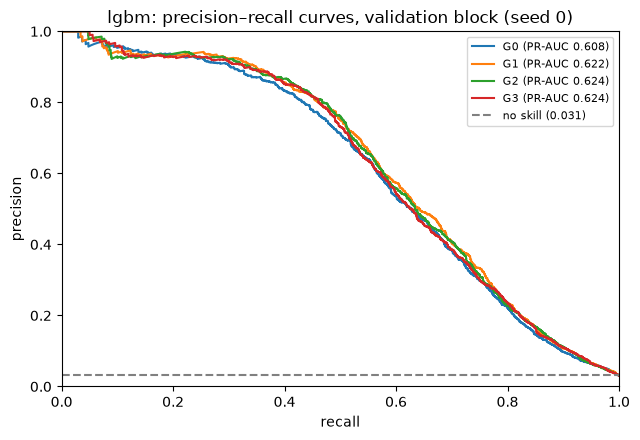

In [8]:
fig, ax = plt.subplots(figsize=(6.5, 4.5))
for name in FEATURE_SETS:
    path = PREDS_DIR / f"{model.NAME}_{name}_val_seed0.parquet"
    if path.exists():
        p = pd.read_parquet(path)
        precision, recall, _ = precision_recall_curve(p["isFraud"], p["score"])
        ax.plot(recall, precision, label=f"{name} (PR-AUC {val.loc[name, 'pr_auc_mean']:.3f})", lw=1.5)
ax.axhline(fraud_val / n_val, ls="--", color="grey", label=f"no skill ({fraud_val / n_val:.3f})")
ax.set_xlabel("recall"); ax.set_ylabel("precision"); ax.set_xlim(0, 1); ax.set_ylim(0, 1)
ax.set_title(f"{model.NAME}: precision–recall curves, validation block (seed 0)")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

### 5.3 What each feature group adds
Change in mean validation PR-AUC from one set to the next (same settings on every set when `TUNE_ON` is a set name).

,G0 → G1,G1 → G2,G2 → G3,G0 → G3
change in PR-AUC,0.0144,0.0017,0.0002,0.0164


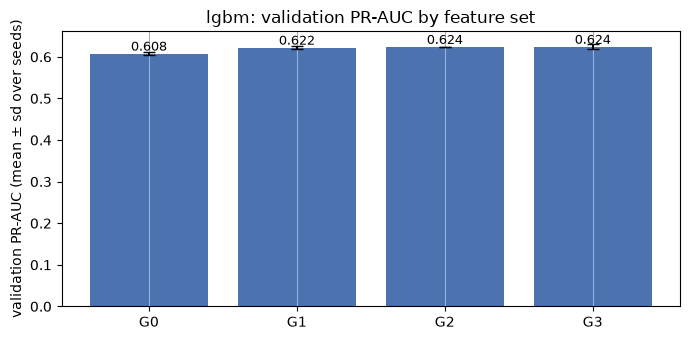

In [9]:
pr = val["pr_auc_mean"]
gains = {f"{a} → {b}": pr[b] - pr[a] for a, b in zip(FEATURE_SETS[:-1], FEATURE_SETS[1:])}
if len(FEATURE_SETS) > 2:
    gains[f"{FEATURE_SETS[0]} → {FEATURE_SETS[-1]}"] = pr[FEATURE_SETS[-1]] - pr[FEATURE_SETS[0]]
display(pd.DataFrame([gains], index=["change in PR-AUC"]).round(4))

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(val.index, val["pr_auc_mean"], yerr=val["pr_auc_std"].fillna(0), color="#4C72B0", capsize=4)
for x, y in zip(val.index, val["pr_auc_mean"]):
    ax.text(x, y, f"{y:.3f}", ha="center", va="bottom", fontsize=9)
ax.set_ylabel("validation PR-AUC (mean ± sd over seeds)")
ax.set_title(f"{model.NAME}: validation PR-AUC by feature set")
ax.grid(axis="x")
fig.tight_layout()
plt.show()

### 5.4 Known vs unknown customers
A validation row is **known** if its `uid` appears in the training block (`src/segments.py`). PR-AUC is the mean over
the seeds, with a 95% bootstrap interval over rows (`N_BOOT` resamples). `10_model_comparison.ipynb` shows the same
split for all models side by side.

In [10]:
N_BOOT = 200
known = segments.known_uid(df["uid"].iloc[val_idx], set(df["uid"].iloc[train_idx]))
rows = []
for name in FEATURE_SETS:
    paths = [PREDS_DIR / f"{model.NAME}_{name}_val_seed{s}.parquet" for s in SEEDS]
    if not all(p.exists() for p in paths):
        print(f"{name}: validation scores not saved for every seed, skipped")
        continue
    preds = [pd.read_parquet(p) for p in paths]
    if not all((p["TransactionID"].to_numpy() == df["TransactionID"].iloc[val_idx].to_numpy()).all() for p in preds):
        raise ValueError(f"{name}: saved scores don't match the validation rows")
    t = segments.segment_pr_auc(preds[0]["isFraud"].to_numpy(), [p["score"].to_numpy() for p in preds], known,
                                n_boot=N_BOOT)
    rows.append(t.assign(feature_set=name))
if rows:
    seg = pd.concat(rows, ignore_index=True)
    display(seg.groupby("segment")[["rows", "fraud"]].first())
    seg["PR-AUC [95% interval]"] = (seg["pr_auc"].map("{:.4f}".format) + " [" + seg["low"].map("{:.3f}".format)
                                    + ", " + seg["high"].map("{:.3f}".format) + "]")
    display(seg.pivot(index="feature_set", columns="segment", values="PR-AUC [95% interval]").reindex(FEATURE_SETS))

,rows,fraud
segment,,
known,28685,640
unknown,30369,1211


segment,known,unknown
feature_set,,
G0,"0.7539 [0.721, 0.786]","0.5477 [0.523, 0.578]"
G1,"0.7831 [0.750, 0.815]","0.5508 [0.526, 0.582]"
G2,"0.7952 [0.762, 0.825]","0.5467 [0.524, 0.578]"
G3,"0.7992 [0.768, 0.830]","0.5466 [0.523, 0.579]"


### 5.5 How the settings affect performance (RQ4)

Read from the tuning runs already in the log, with no extra training: for each tuned setting and each value it
took, the mean time-CV PR-AUC of the combinations tried with that value (dot), and the best and worst of them
(bar). The star marks the chosen value. This model uses random search (20 combinations), so each value is paired with a different mix of other settings; treat the means as indicative, not as a controlled one-at-a-time sweep. The number of trees (boosting models) or epochs (MLP) is not
a tuned setting: early stopping picks it in every fit.

,setting,value,mean,best,worst,combinations
0,learning_rate,0.03,0.5793,0.5870,0.5694,9
1,learning_rate,0.1,0.5699,0.5862,0.5431,11
2,min_child_samples,100,0.5705,0.5864,0.5431,8
3,min_child_samples,20,0.5756,0.5830,0.5583,8
4,min_child_samples,300,0.5786,0.5870,0.5733,4
5,num_leaves,127,0.5818,0.5870,0.5776,8
6,num_leaves,31,0.5619,0.5797,0.5431,6
7,num_leaves,63,0.5762,0.5864,0.5694,6
8,reg_lambda,1.0,0.5714,0.5864,0.5431,8
9,reg_lambda,3.0,0.5725,0.5821,0.5475,5


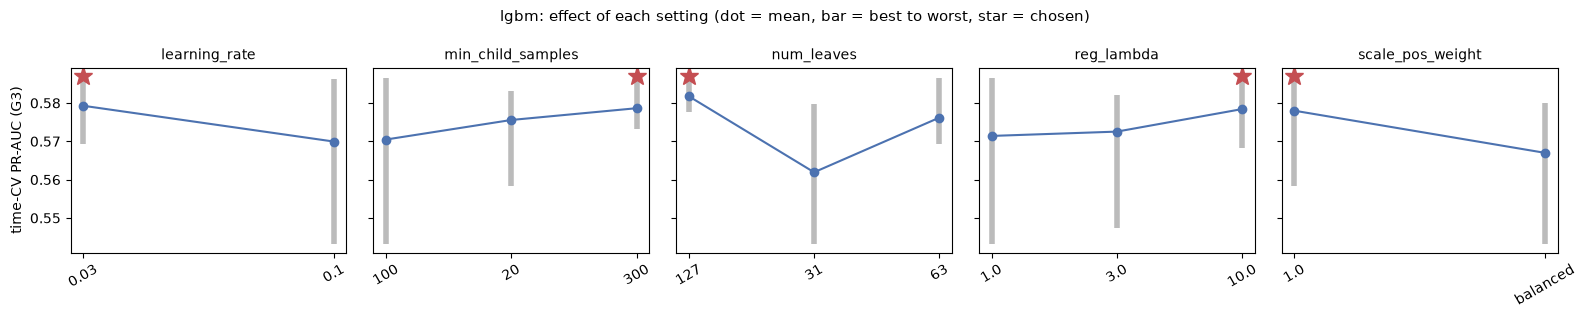

In [11]:
SENS_SET = TUNE_ON or FEATURE_SETS[-1]
sens = experiment.setting_sensitivity(model.NAME, SENS_SET, LOG_PATH)
if sens.empty:
    print("Fewer than two values tried for every setting: nothing to show.")
else:
    display(sens.round(4))
    settings_ = list(dict.fromkeys(sens["setting"]))
    n = len(settings_)
    fig, axes = plt.subplots(1, n, figsize=(3.2 * n, 3.2), sharey=True, squeeze=False)
    for ax, name in zip(axes[0], settings_):
        part = sens[sens["setting"] == name].reset_index(drop=True)
        x = range(len(part))
        ax.vlines(x, part["worst"], part["best"], color="#BBBBBB", lw=4)
        ax.plot(x, part["mean"], "o-", color="#4C72B0")
        picked = chosen[SENS_SET].get(name)
        for i, v in enumerate(part["value"]):
            if v == picked or (picked is None and v == "none"):
                ax.plot(i, part.loc[i, "best"], "*", ms=14, color="#C44E52")
        ax.set_xticks(list(x), [str(v) for v in part["value"]], rotation=30)
        ax.set_title(name, fontsize=10)
    axes[0][0].set_ylabel(f"time-CV PR-AUC ({SENS_SET})")
    fig.suptitle(f"{model.NAME}: effect of each setting (dot = mean, bar = best to worst, star = chosen)", fontsize=11)
    fig.tight_layout()
    plt.show()

## 6. Feature importance

For the chosen settings on `IMPORTANCE_SET` (G3 by default), refit on the training block exactly as in the seed-0
validation run (cached in `results/models/`, so this runs once), then measure:

- **Permutation importance:** how much validation PR-AUC drops when one input column is shuffled (on
  `IMPORTANCE_ROWS` validation rows). It means the same thing for every model, so it can be compared across notebooks.
- **Built-in importance:** total gain of the splits on each input.

Correlated columns share credit: shuffling one leaves its near-copy in place, so a small drop does not prove a column
is useless. Importances describe what this model relies on, not causes of fraud. The table is also saved to
`results/importance/` for `10_model_comparison.ipynb`.

In [12]:
cols = sets[IMPORTANCE_SET]
fitted, pipe = experiment.fit_final(model, lambda: make_pipeline(cols), df, train_idx, chosen[IMPORTANCE_SET],
                                    IMPORTANCE_SET, seed=0, cache_dir=MODELS_DIR)
X_val = pipe.transform(df.iloc[val_idx])
y_val = df["isFraud"].iloc[val_idx].to_numpy()
group_of = importance.feature_groups(spec)

perm = importance.permutation(fitted, X_val, y_val, cols, n_rows=IMPORTANCE_ROWS, seed=0)
built_in = importance.intrinsic(model, fitted, list(X_val.columns), cols)
imp = perm[["pr_auc_drop"]].assign(group=[group_of.get(c, "?") for c in perm.index])
if built_in is not None:
    imp["built_in"] = built_in
    imp["built_in_share"] = built_in / built_in.sum()
imp = imp.sort_values("pr_auc_drop", ascending=False)
print(f"PR-AUC on the {min(IMPORTANCE_ROWS, len(val_idx)):,} rows used: {perm['base_pr_auc'].iloc[0]:.4f} "
      f"(built-in importance: {model.IMPORTANCE or 'none'})")
IMPORTANCE_DIR.mkdir(parents=True, exist_ok=True)
imp.assign(model=model.NAME, feature_set=IMPORTANCE_SET).to_csv(IMPORTANCE_DIR / f"{model.NAME}_{IMPORTANCE_SET}.csv")
display(imp.head(20).round(4))

/Users/damienkoh/Downloads/Dom bt4012/bt4012/.venv/lib/python3.12/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


PR-AUC on the 20,000 rows used: 0.6063 (built-in importance: total gain)


,pr_auc_drop,group,built_in,built_in_share
feature,,,,
C1,0.0734,G0_raw,78247.0603,0.0433
TransactionAmt,0.0358,G0_raw,37127.7824,0.0206
card1,0.0340,G0_raw,46468.1656,0.0257
fe_freq_card1,0.0317,G2_card_device_history,46069.5601,0.0255
fe_D1n,0.0310,G1_row_level,58804.6880,0.0326
card2,0.0279,G0_raw,46249.6199,0.0256
C14,0.0252,G0_raw,61666.2129,0.0342
fe_D15n,0.0226,G1_row_level,39572.1776,0.0219
C13,0.0223,G0_raw,49184.9570,0.0272


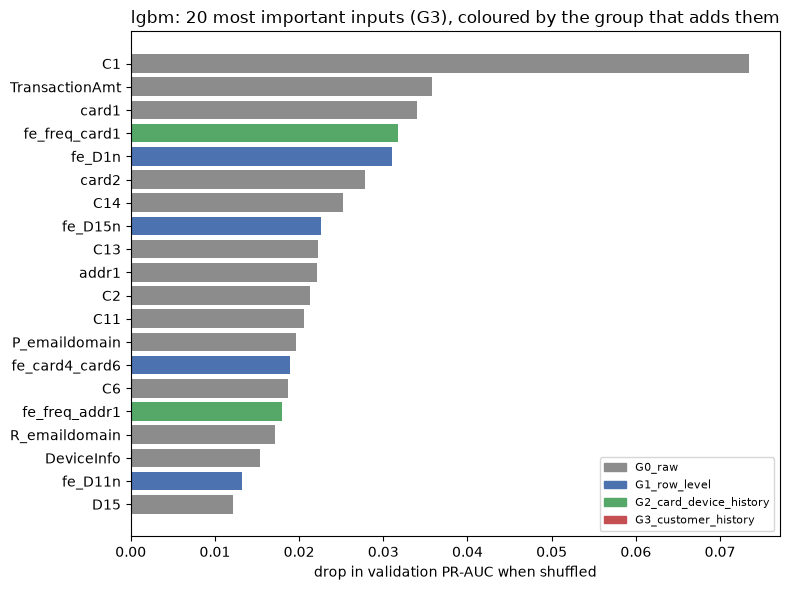

Total PR-AUC drop by feature group (sum over its columns; groups overlap in what they capture):


,sum,count
group,,
G0_raw,0.5159,197
G1_row_level,0.1273,27
G2_card_device_history,0.0643,10
G3_customer_history,0.0140,18


In [13]:
top = imp.head(20).iloc[::-1]
colors = {"G0_raw": "#8C8C8C", "G1_row_level": "#4C72B0", "G2_card_device_history": "#55A868",
          "G3_customer_history": "#C44E52"}
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(top.index, top["pr_auc_drop"], color=[colors.get(g, "#999999") for g in top["group"]])
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in colors.values()]
ax.legend(handles, list(colors), fontsize=8, loc="lower right")
ax.set_xlabel("drop in validation PR-AUC when shuffled")
ax.set_title(f"{model.NAME}: 20 most important inputs ({IMPORTANCE_SET}), coloured by the group that adds them")
fig.tight_layout()
plt.show()

print("Total PR-AUC drop by feature group (sum over its columns; groups overlap in what they capture):")
display(imp.groupby("group")["pr_auc_drop"].agg(["sum", "count"]).sort_values("sum", ascending=False).round(4))

## 7. Findings

- **Validation and feature groups:** mean PR-AUC over seeds 0–2 is G0 **0.6076 ± 0.0037**, G1 **0.6221 ± 0.0042**, G2 **0.6238 ± 0.0009**, and G3 **0.6240 ± 0.0058** (sample standard deviation). G3 has the highest mean, improving on G0 by **0.0164**. Most of the gain comes from row-level features (G0 → G1: **+0.0144**); card/device history adds **+0.0017**, and customer history adds **+0.0002**. The G2–G3 difference is small relative to the seed spread, so it does not establish a clear overall gain from customer history.

- **Known versus unknown customers:** on G3, mean PR-AUC is **0.7992 [0.768, 0.830]** for known customers and **0.5466 [0.523, 0.579]** for unknown ones (95% bootstrap intervals from section 5.4). Across G0 → G3, the known-customer mean rises from **0.7539** to **0.7992**, while the unknown-customer mean changes from **0.5477** to **0.5466**. This pattern suggests that the added features help mainly customers already represented in training; it is not a causal or significance claim.

- **Selected settings and search limits:** the G3 time-CV search selected `learning_rate=0.03`, `num_leaves=127`, `min_child_samples=300`, `reg_lambda=10.0`, and `scale_pos_weight=1.0` (mean CV PR-AUC **0.5870**). The selected learning rate is at the lower edge, and leaves, minimum child size and L2 regularisation are at their upper edges. The best configuration is therefore conditional on the tried search space; no wider search was run. The same selected settings were used for G0–G3.

- **RQ4 and seed variation:** in section 5.5, `num_leaves` has the largest marginal mean-CV range (**0.5619** for 31 versus **0.5818** for 127). Learning rate 0.03, L2 10 and no positive-class upweighting also have higher marginal means in this search. Because the 20 configurations were randomly sampled, values are paired with different settings of the other parameters; these are indicative comparisons, not controlled one-at-a-time effects. G3 has the largest validation seed standard deviation (**0.0058**), while G2 is the most stable (**0.0009**).

- **Feature importance:** the largest G3 permutation PR-AUC drops are for raw `C1` (**0.0734**), `TransactionAmt` (**0.0358**) and `card1` (**0.0340**). Engineered `fe_freq_card1` (**0.0317**) and `fe_D1n` (**0.0310**) rank fourth and fifth, supporting the relevance of past card activity and normalised time deltas identified in the EDA. The customer-history group has a smaller summed drop (**0.0140**) than the row-level (**0.1273**) or card/device-history (**0.0643**) groups. These sums are not additive performance contributions because correlated features share information; importance was measured on a 20,000-row validation sample.

- **Evaluation protocol:** this run uses the shared G0–G3 setup with a 3,000-tree cap and two-step early stopping (`es_setup=2`): the stopping point is chosen inside training, then validation and saved-fold models are refit on the full training portion. All figures above are validation or training-block CV findings. The reserved test block remains unscored.